In [198]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

from scipy.cluster.hierarchy import dendrogram, linkage

In [199]:
df=pd.read_csv("/content/adult_dataset.csv")
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


In [200]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             46400 non-null  float64
 1   workclass       45480 non-null  object 
 2   fnlwgt          48842 non-null  int64  
 3   education       48842 non-null  object 
 4   education-num   48842 non-null  int64  
 5   marital-status  48842 non-null  object 
 6   occupation      45485 non-null  object 
 7   relationship    48842 non-null  object 
 8   race            48842 non-null  object 
 9   sex             48842 non-null  object 
 10  capital-gain    48842 non-null  int64  
 11  capital-loss    48842 non-null  int64  
 12  hours-per-week  46400 non-null  float64
 13  native-country  46137 non-null  object 
 14  income          48842 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 5.6+ MB


In [201]:
df.duplicated().sum()

np.int64(16)

In [202]:
df.drop_duplicates(inplace=True)

In [203]:
df.duplicated().sum()

np.int64(0)

In [204]:
df.isnull().sum()

,0
age,2442
workclass,3362
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,3357
relationship,0
race,0
sex,0


In [205]:
round(df.isnull().mean()*100, 2)

,0
age,5.00
workclass,6.89
fnlwgt,0.00
education,0.00
education-num,0.00
marital-status,0.00
occupation,6.88
relationship,0.00
race,0.00
sex,0.00


In [206]:
df['age'] = df['age'].fillna(df['age'].median())

df['fnlwgt'] = df['fnlwgt'].fillna(df['fnlwgt'].median())

df['education-num'] = df['education-num'].fillna(df['education-num'].median())

df['capital-gain'] = df['capital-gain'].fillna(df['capital-gain'].median())

df['capital-loss'] = df['capital-loss'].fillna(df['capital-loss'].median())

df['hours-per-week'] = df['hours-per-week'].fillna(df['hours-per-week'].median())

In [207]:
df['workclass'] = df['workclass'].fillna(df['workclass'].mode()[0])

df['education'] = df['education'].fillna(df['education'].mode()[0])

df['marital-status'] = df['marital-status'].fillna(df['marital-status'].mode()[0])

df['occupation'] = df['occupation'].fillna(df['occupation'].mode()[0])

df['relationship'] = df['relationship'].fillna(df['relationship'].mode()[0])

df['race'] = df['race'].fillna(df['race'].mode()[0])

df['sex'] = df['sex'].fillna(df['sex'].mode()[0])

df['native-country'] = df['native-country'].fillna(df['native-country'].mode()[0])

In [208]:
df.isnull().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0


In [209]:
df.drop('income', axis=1, inplace=True)

print(df.head())

    age         workclass  fnlwgt  education  education-num  \
0  39.0         State-gov   77516  Bachelors             13   
1  50.0  Self-emp-not-inc   83311  Bachelors             13   
2  38.0           Private  215646    HS-grad              9   
3  53.0           Private  234721       11th              7   
4  28.0           Private  338409  Bachelors             13   

       marital-status         occupation   relationship   race     sex  \
0       Never-married       Adm-clerical  Not-in-family  White    Male   
1  Married-civ-spouse    Exec-managerial        Husband  White    Male   
2            Divorced  Handlers-cleaners  Not-in-family  White    Male   
3  Married-civ-spouse  Handlers-cleaners        Husband  Black    Male   
4  Married-civ-spouse     Prof-specialty           Wife  Black  Female   

   capital-gain  capital-loss  hours-per-week native-country  
0          2174             0            40.0  United-States  
1             0             0            13.0  Uni

In [210]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48826.000000,4.882600e+04,48826.000000,48826.000000,48826.000000,48826.000000
mean,38.597428,1.896605e+05,10.078278,1079.421230,87.530988,40.428481
std,13.602653,1.056025e+05,2.570759,7453.214369,403.067466,12.326046
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175550e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781385e+05,10.000000,0.000000,0.000000,40.000000
75%,47.000000,2.376170e+05,12.000000,0.000000,0.000000,45.000000
max,255.000000,1.490400e+06,16.000000,99999.000000,4356.000000,250.000000


In [211]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 48826 entries, 0 to 48841
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             48826 non-null  float64
 1   workclass       48826 non-null  object 
 2   fnlwgt          48826 non-null  int64  
 3   education       48826 non-null  object 
 4   education-num   48826 non-null  int64  
 5   marital-status  48826 non-null  object 
 6   occupation      48826 non-null  object 
 7   relationship    48826 non-null  object 
 8   race            48826 non-null  object 
 9   sex             48826 non-null  object 
 10  capital-gain    48826 non-null  int64  
 11  capital-loss    48826 non-null  int64  
 12  hours-per-week  48826 non-null  float64
 13  native-country  48826 non-null  object 
dtypes: float64(2), int64(4), object(8)
memory usage: 5.6+ MB


In [212]:
cat_col=df.select_dtypes(include="O").columns
cat_col

Index(['workclass', 'education', 'marital-status', 'occupation',
       'relationship', 'race', 'sex', 'native-country'],
      dtype='object')

In [213]:
num_col=df.select_dtypes(include="number").columns
num_col

Index(['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss',
       'hours-per-week'],
      dtype='object')

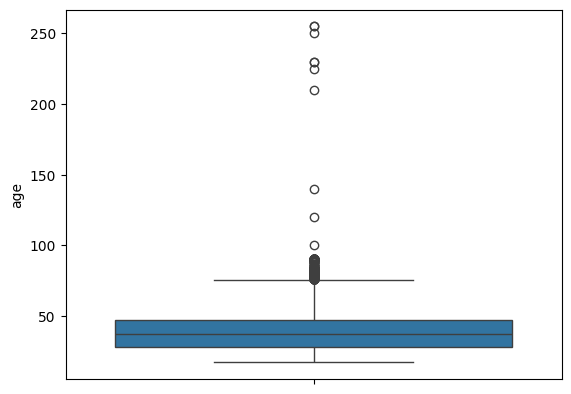

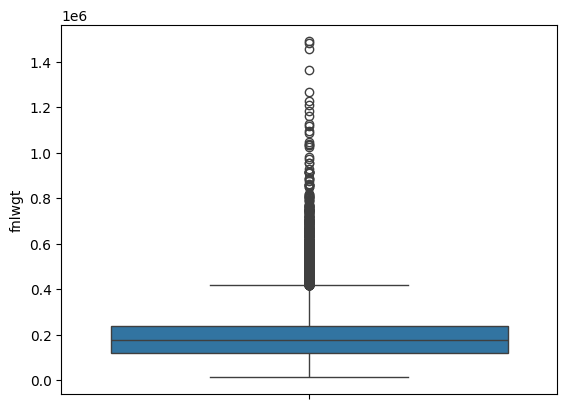

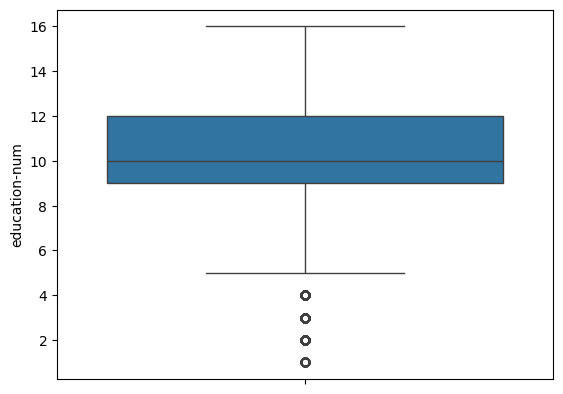

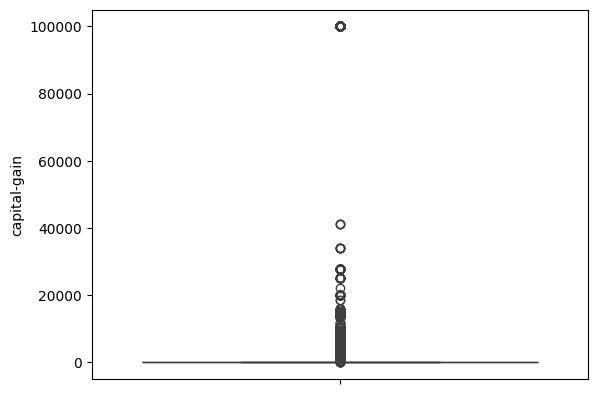

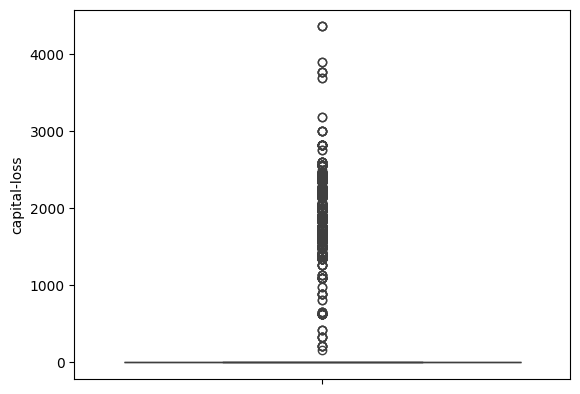

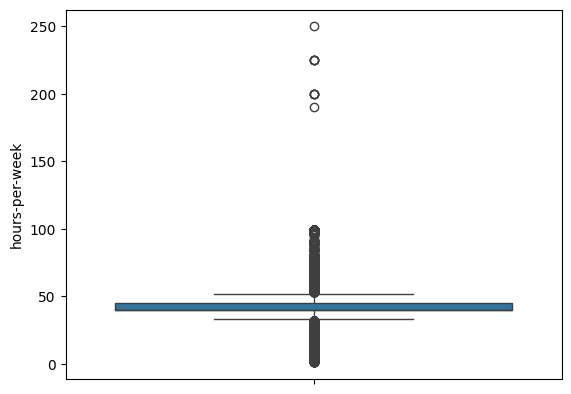

In [214]:
import seaborn as sns
import matplotlib.pyplot as plt
for i in num_col:
  sns.boxplot(df[i])
  plt.show(i)

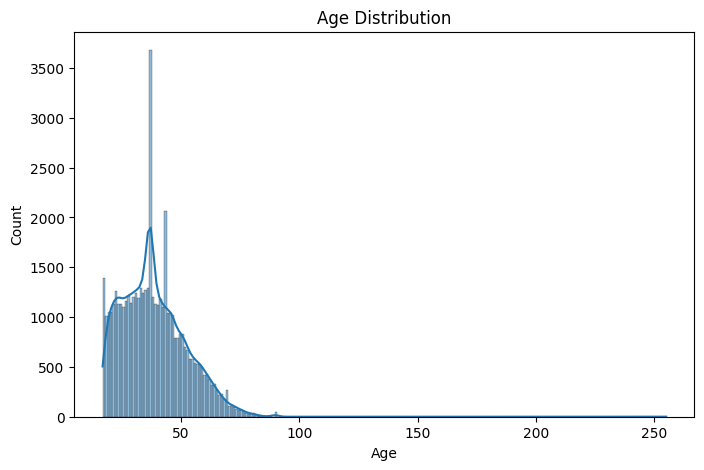

In [215]:
plt.figure(figsize=(8,5))

sns.histplot(df['age'], kde=True)

plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')

plt.show()

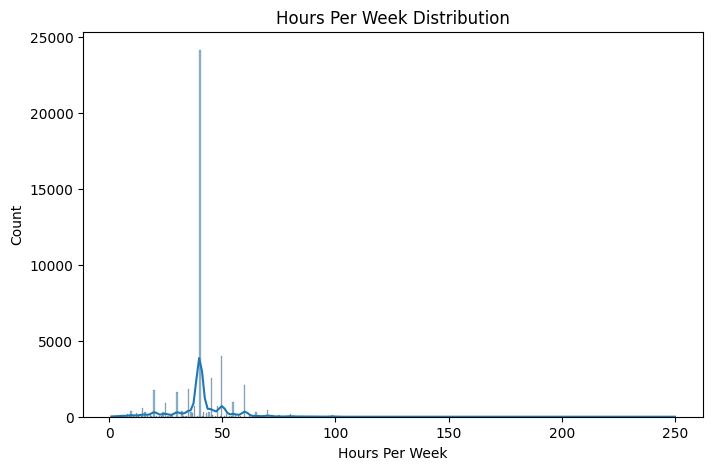

In [216]:
plt.figure(figsize=(8,5))

sns.histplot(df['hours-per-week'], kde=True)

plt.title('Hours Per Week Distribution')
plt.xlabel('Hours Per Week')
plt.ylabel('Count')

plt.show()

In [217]:
df.select_dtypes("number").skew()

,0
age,1.017826
fnlwgt,1.439357
education-num,-0.315970
capital-gain,11.892692
capital-loss,4.568956
hours-per-week,0.812937


In [218]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48826.000000,4.882600e+04,48826.000000,48826.000000,48826.000000,48826.000000
mean,38.597428,1.896605e+05,10.078278,1079.421230,87.530988,40.428481
std,13.602653,1.056025e+05,2.570759,7453.214369,403.067466,12.326046
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175550e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781385e+05,10.000000,0.000000,0.000000,40.000000
75%,47.000000,2.376170e+05,12.000000,0.000000,0.000000,45.000000
max,255.000000,1.490400e+06,16.000000,99999.000000,4356.000000,250.000000


In [219]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,United-States
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba


In [220]:
df['capital-gain'] = np.log1p(df['capital-gain'])

df['capital-loss'] = np.log1p(df['capital-loss'])

In [221]:
print("Capital Gain:", df['capital-gain'].skew())

print("Capital Loss:", df['capital-loss'].skew())

Capital Gain: 3.112972019493486
Capital Loss: 4.302144302380041


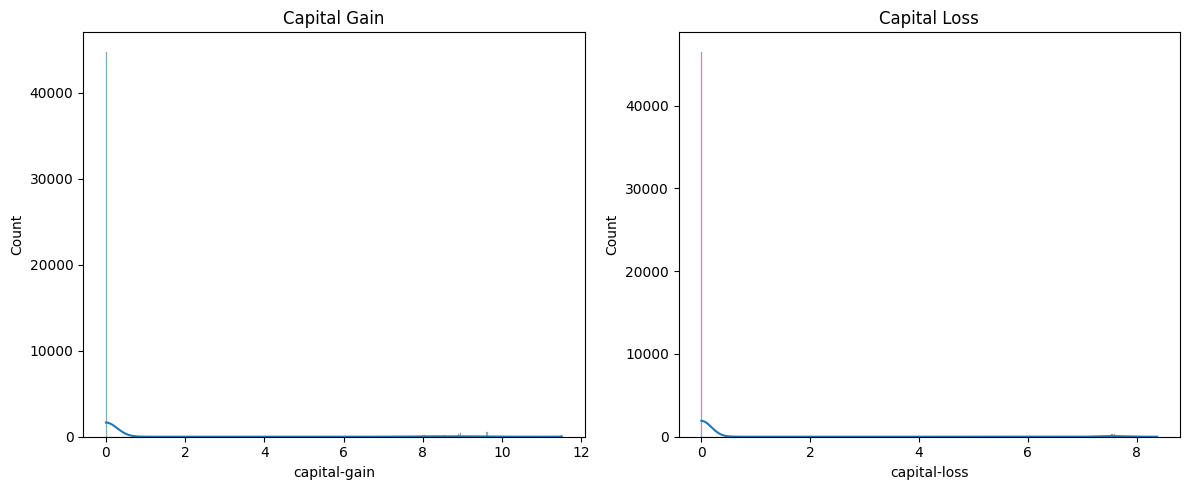

In [222]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.histplot(df['capital-gain'], kde=True)
plt.title('Capital Gain')

plt.subplot(1,2,2)
sns.histplot(df['capital-loss'], kde=True)
plt.title('Capital Loss')

plt.tight_layout()
plt.show()

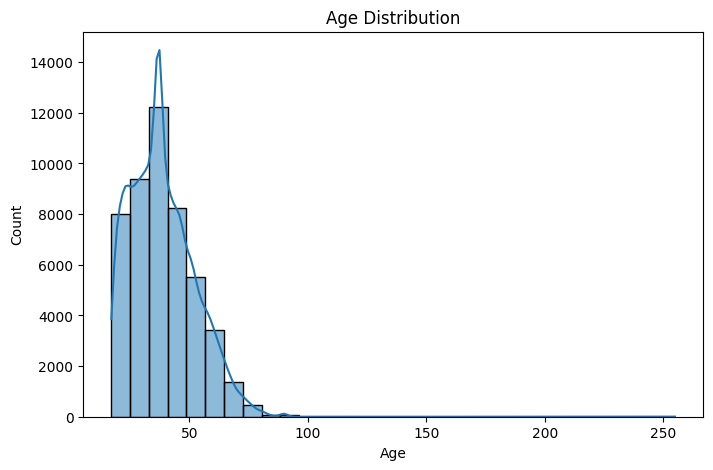

In [223]:
plt.figure(figsize=(8,5))

sns.histplot(df['age'], bins=30, kde=True)

plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')

plt.show()

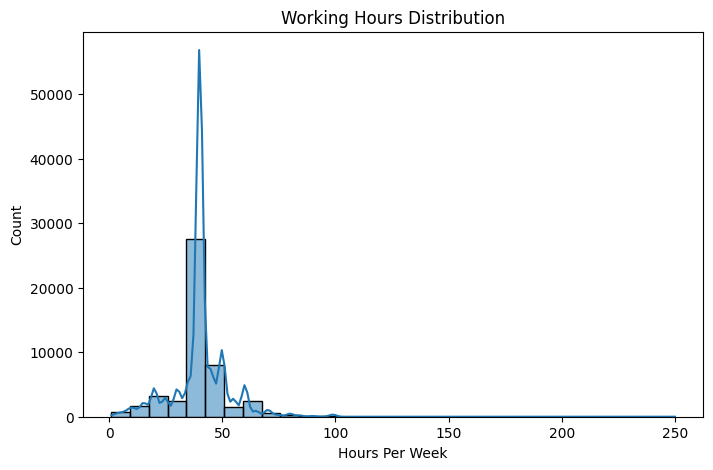

In [224]:
plt.figure(figsize=(8,5))

sns.histplot(df['hours-per-week'], bins=30, kde=True)

plt.title('Working Hours Distribution')
plt.xlabel('Hours Per Week')
plt.ylabel('Count')

plt.show()

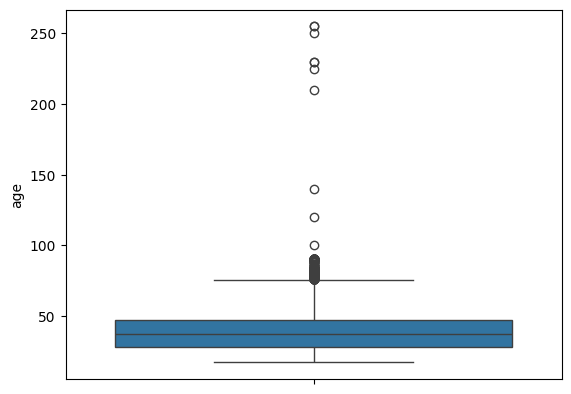

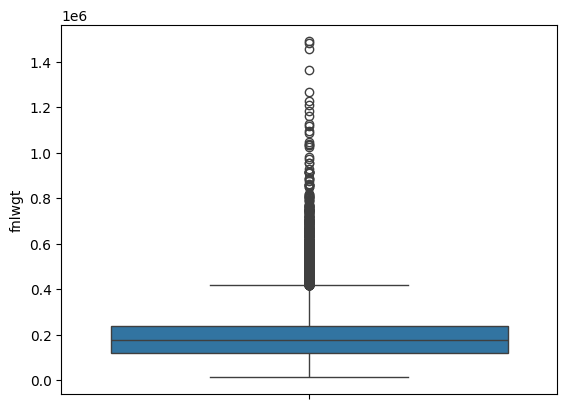

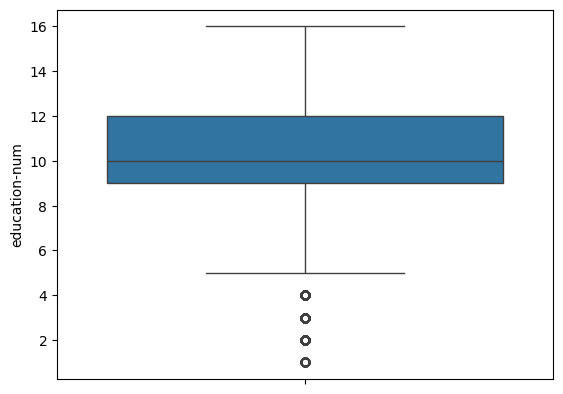

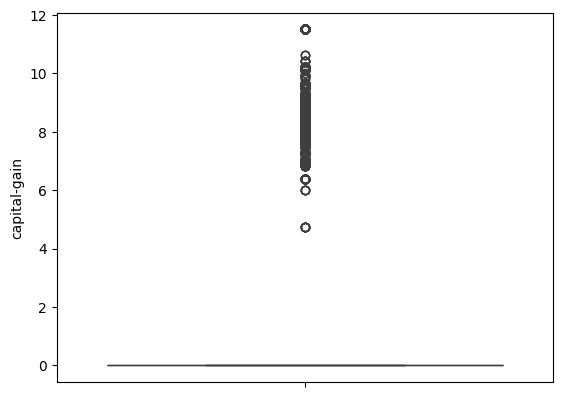

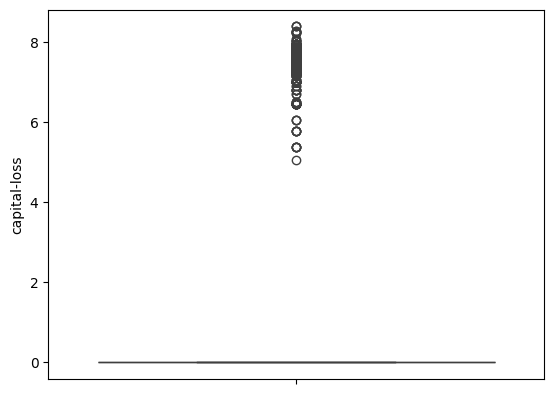

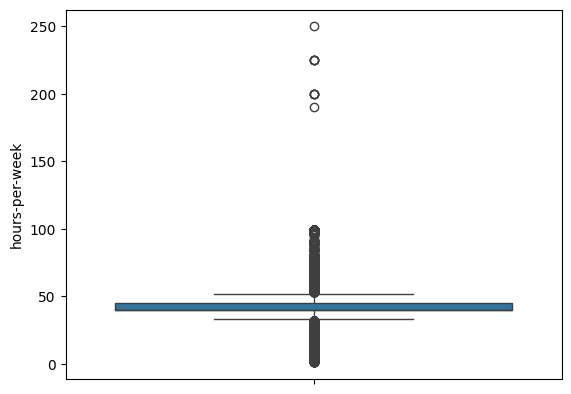

In [225]:
for i in num_col:
  sns.boxplot(df[i])
  plt.show(i)

In [226]:
outlier_cols = [
    'age',
    'fnlwgt',
    'education-num',
    'capital-gain',
    'capital-loss',
    'hours-per-week'
]

for col in outlier_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower, upper)

print("Outliers treated successfully")

Outliers treated successfully


In [227]:
print("Capital Gain Skewness:")
print(df['capital-gain'].skew())

print("Capital Loss Skewness:")
print(df['capital-loss'].skew())

Capital Gain Skewness:
0.0
Capital Loss Skewness:
0.0


In [228]:
df.select_dtypes("number").skew()

,0
age,0.530100
fnlwgt,0.555022
education-num,-0.035350
capital-gain,0.000000
capital-loss,0.000000
hours-per-week,0.480415


In [229]:
df.select_dtypes(include='object').head()

,workclass,education,marital-status,occupation,relationship,race,sex,native-country
0,State-gov,Bachelors,Never-married,Adm-clerical,Not-in-family,White,Male,United-States
1,Self-emp-not-inc,Bachelors,Married-civ-spouse,Exec-managerial,Husband,White,Male,United-States
2,Private,HS-grad,Divorced,Handlers-cleaners,Not-in-family,White,Male,United-States
3,Private,11th,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,United-States
4,Private,Bachelors,Married-civ-spouse,Prof-specialty,Wife,Black,Female,Cuba


In [230]:
df = pd.get_dummies(
    df,
    columns=df.select_dtypes(include=['object']).columns,
    drop_first=True,
    dtype=int
)

print(df.head())

print(df.shape)

    age  fnlwgt  education-num  capital-gain  capital-loss  hours-per-week  \
0  39.0   77516           13.0           0.0           0.0            40.0   
1  50.0   83311           13.0           0.0           0.0            32.5   
2  38.0  215646            9.0           0.0           0.0            40.0   
3  53.0  234721            7.0           0.0           0.0            40.0   
4  28.0  338409           13.0           0.0           0.0            40.0   

   workclass_Federal-gov  workclass_Local-gov  workclass_Never-worked  \
0                      0                    0                       0   
1                      0                    0                       0   
2                      0                    0                       0   
3                      0                    0                       0   
4                      0                    0                       0   

   workclass_Private  ...  native-country_Portugal  \
0                  0  ...             

In [231]:
df.dtypes

,0
age,float64
fnlwgt,int64
education-num,float64
capital-gain,float64
capital-loss,float64
...,...
native-country_Thailand,int64
native-country_Trinadad&Tobago,int64
native-country_United-States,int64
native-country_Vietnam,int64


In [232]:
scaler = StandardScaler()

scaled_data = scaler.fit_transform(df)

scaled_df = pd.DataFrame(
    scaled_data,
    columns=df.columns
)

print(scaled_df.head())

        age    fnlwgt  education-num  capital-gain  capital-loss  \
0  0.035123 -1.146152       1.171344           0.0           0.0   
1  0.864064 -1.085355       1.171344           0.0           0.0   
2 -0.040236  0.303009      -0.456772           0.0           0.0   
3  1.090139  0.503130      -1.270830           0.0           0.0   
4 -0.793819  1.590950       1.171344           0.0           0.0   

   hours-per-week  workclass_Federal-gov  workclass_Local-gov  \
0       -0.187370              -0.168371            -0.254632   
1       -1.430414              -0.168371            -0.254632   
2       -0.187370              -0.168371            -0.254632   
3       -0.187370              -0.168371            -0.254632   
4       -0.187370              -0.168371            -0.254632   

   workclass_Never-worked  workclass_Private  ...  native-country_Portugal  \
0               -0.013578          -1.637828  ...                -0.036791   
1               -0.013578          -1.637828

KMEANS

In [233]:
from sklearn.cluster import KMeans #knn, dt, rf
kmeans = KMeans(n_clusters=6,init="k-means++",n_init=15, max_iter=300)  # Example with 3 clusters
df['Cluster'] = kmeans.fit_predict(scaled_df)
df

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,...,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia,Cluster
0,39.0,77516,13.0,0.0,0.0,40.0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,4
1,50.0,83311,13.0,0.0,0.0,32.5,0,0,0,0,...,0,0,0,0,0,0,1,0,0,1
2,38.0,215646,9.0,0.0,0.0,40.0,0,0,0,1,...,0,0,0,0,0,0,1,0,0,4
3,53.0,234721,7.0,0.0,0.0,40.0,0,0,0,1,...,0,0,0,0,0,0,1,0,0,1
4,28.0,338409,13.0,0.0,0.0,40.0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48837,39.0,215419,13.0,0.0,0.0,36.0,0,0,0,1,...,0,0,0,0,0,0,1,0,0,4
48838,64.0,321403,9.0,0.0,0.0,40.0,0,0,0,1,...,0,0,0,0,0,0,1,0,0,2
48839,38.0,374983,13.0,0.0,0.0,50.0,0,0,0,1,...,0,0,0,0,0,0,1,0,0,1
48840,44.0,83891,13.0,0.0,0.0,40.0,0,0,0,1,...,0,0,0,0,0,0,1,0,0,0


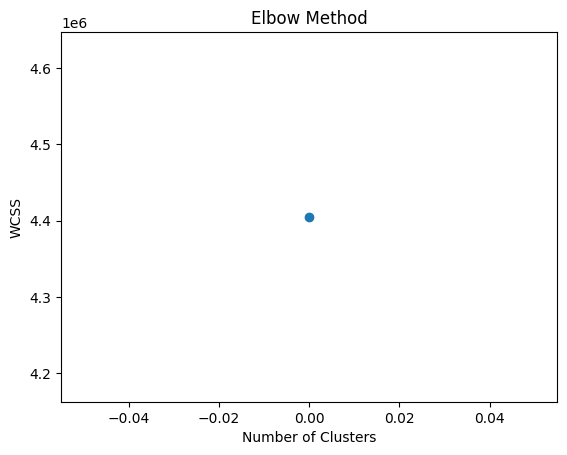

In [234]:
plt.plot(kmeans.inertia_,
         marker='o')

plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.title('Elbow Method')

plt.show()

Silhouette Score

In [235]:
kmeans = KMeans(n_clusters=6, random_state=42, n_init=10)

labels = kmeans.fit_predict(scaled_data[:5000])

score = silhouette_score(scaled_data[:5000], labels)

print("Silhouette Score:", score)

Silhouette Score: 0.028735533989642254


In [236]:
kmeans = KMeans(n_clusters=6, random_state=42, n_init=10)

df['cluster'] = kmeans.fit_predict(scaled_data)

print(df['cluster'].value_counts())

cluster
2    20890
0    17486
3     7215
1     3074
5       87
4       74
Name: count, dtype: int64


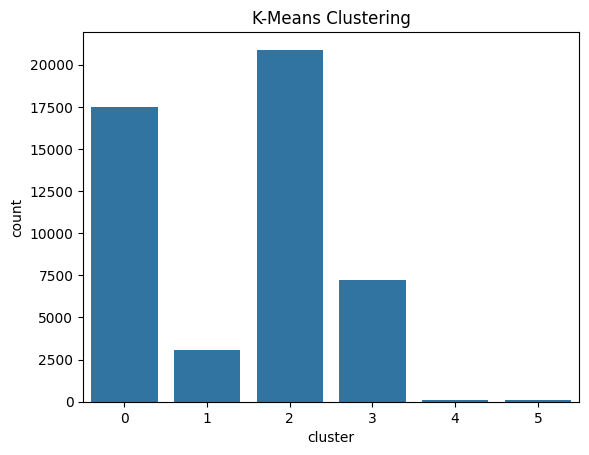

In [237]:
sns.countplot(data=df, x='cluster')

plt.title('K-Means Clustering')

plt.show()

Agglomerative Clustering

In [238]:
agglo = AgglomerativeClustering(n_clusters=6)

agglo_labels = agglo.fit_predict(scaled_data[:2000])

print(agglo_labels)

[0 0 0 ... 0 0 0]


In [239]:
print(pd.Series(agglo_labels).value_counts())

0    1918
2      72
1       4
5       2
4       2
3       2
Name: count, dtype: int64


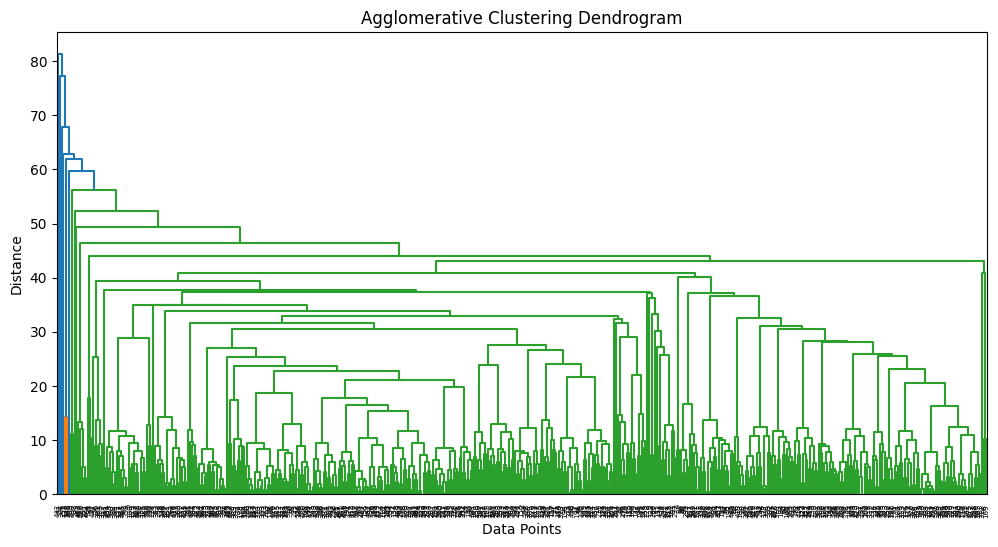

In [240]:

linked = linkage(scaled_data[:500], method='ward')

plt.figure(figsize=(12,6))

dendrogram(linked)

plt.title('Agglomerative Clustering Dendrogram')
plt.xlabel('Data Points')
plt.ylabel('Distance')

plt.show()

In [241]:
agglo_score = silhouette_score(
    scaled_data[:2000],
    agglo_labels
)

print("Agglomerative Silhouette Score:", agglo_score)

Agglomerative Silhouette Score: 0.5757669759273315


DBSCAN Clustering

In [242]:
from sklearn.cluster import DBSCAN

In [243]:
dbscan = DBSCAN(eps=0.5, min_samples=5)

dbscan_labels = dbscan.fit_predict(scaled_data[:5000])

print(dbscan_labels)

[-1 -1 -1 ... -1 -1 -1]


In [244]:
print("Noise Points:", list(dbscan_labels).count(-1))

Noise Points: 4791


In [245]:
number_of_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)

print("Number of Clusters:", number_of_clusters)

Number of Clusters: 25


In [246]:
print(pd.Series(dbscan_labels).value_counts())

-1     4791
 0       27
 1       22
 3       21
 5       15
 2        9
 6        9
 8        9
 4        7
 15       7
 7        7
 10       6
 19       6
 20       6
 9        6
 21       5
 24       5
 14       5
 23       5
 13       5
 17       5
 11       5
 16       5
 12       5
 18       4
 22       3
Name: count, dtype: int64


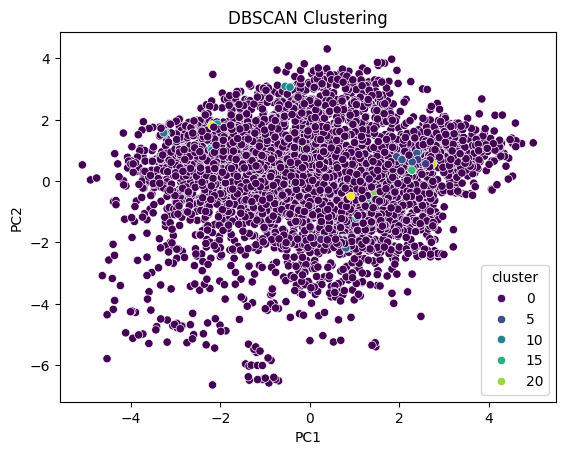

In [247]:
dbscan_pca = pd.DataFrame(
    pca_data[:5000],
    columns=['PC1', 'PC2']
)

dbscan_pca['cluster'] = dbscan_labels

sns.scatterplot(
    data=dbscan_pca,
    x='PC1',
    y='PC2',
    hue='cluster',
    palette='viridis'
)

plt.title('DBSCAN Clustering')
plt.show()

In [248]:
dbscan_data = scaled_data[:5000][dbscan_labels != -1]

dbscan_valid_labels = dbscan_labels[dbscan_labels != -1]

if len(set(dbscan_valid_labels)) > 1:

    dbscan_score = silhouette_score(
        dbscan_data,
        dbscan_valid_labels
    )

    print("DBSCAN Silhouette Score:", dbscan_score)

else:
    print("Silhouette Score cannot be calculated")
    print("Silhouette Score cannot be calculated")

DBSCAN Silhouette Score: 0.5898643888992162


Dimensionality Reduction using PCA

In [249]:
pca = PCA(n_components=2)

pca_data = pca.fit_transform(scaled_data)

print(pca_data)

[[ 0.39097306  3.01500415]
 [ 3.15303493  0.52398057]
 [-0.81272392 -0.78168351]
 ...
 [ 2.26922311  0.83466425]
 [-0.62044709  1.5383174 ]
 [ 3.78849496  0.82050325]]


In [250]:
pca_df = pd.DataFrame(
    pca_data,
    columns=['PC1', 'PC2']
)

pca_df.head()

,PC1,PC2
0,0.390973,3.015004
1,3.153035,0.523981
2,-0.812724,-0.781684
3,-1.146711,-2.071134
4,0.279178,0.071379


In [251]:
print("PC1 Variance:", pca.explained_variance_ratio_[0])

print("PC2 Variance:", pca.explained_variance_ratio_[1])

print("Total Variance:",
      pca.explained_variance_ratio_.sum())

PC1 Variance: 0.034730743226718944
PC2 Variance: 0.027128843046472707
Total Variance: 0.06185958627319165


In [252]:
pca_df['cluster'] = df['cluster'].values

print(pca_df.head())

        PC1       PC2  cluster
0  0.390973  3.015004        0
1  3.153035  0.523981        2
2 -0.812724 -0.781684        0
3 -1.146711 -2.071134        2
4  0.279178  0.071379        1


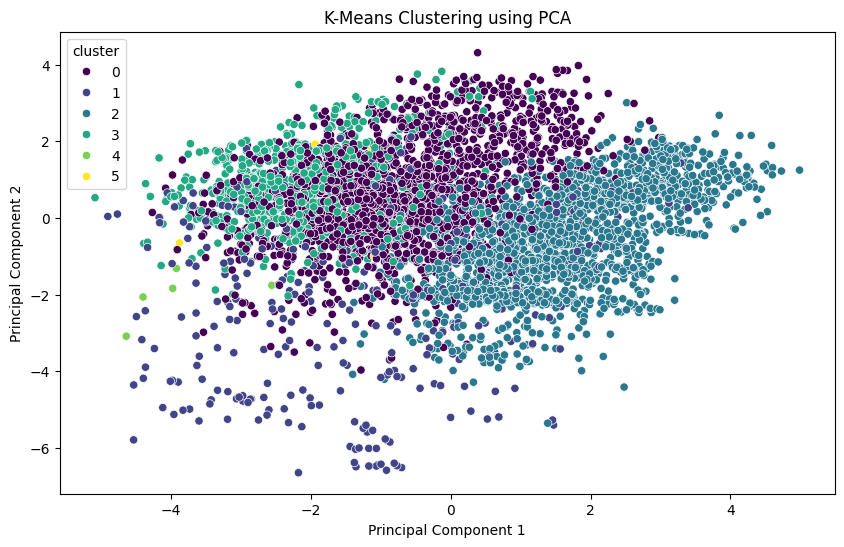

In [253]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=pca_df.iloc[:5000],
    x='PC1',
    y='PC2',
    hue='cluster',
    palette='viridis'
)

plt.title('K-Means Clustering using PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.show()

Agglomerative Clustering Visualization using PCA

In [254]:
agglo_pca = pd.DataFrame(
    pca_data[:2000],
    columns=['PC1', 'PC2']
)

agglo_pca['cluster'] = agglo_labels

print(agglo_pca.head())

        PC1       PC2  cluster
0  0.390973  3.015004        0
1  3.153035  0.523981        0
2 -0.812724 -0.781684        0
3 -1.146711 -2.071134        0
4  0.279178  0.071379        2


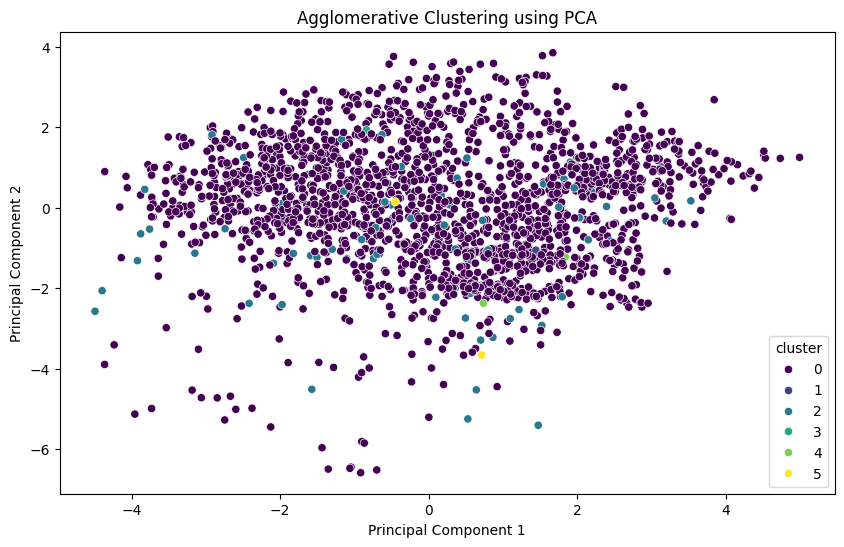

In [255]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=agglo_pca,
    x='PC1',
    y='PC2',
    hue='cluster',
    palette='viridis'
)

plt.title('Agglomerative Clustering using PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')

plt.show()

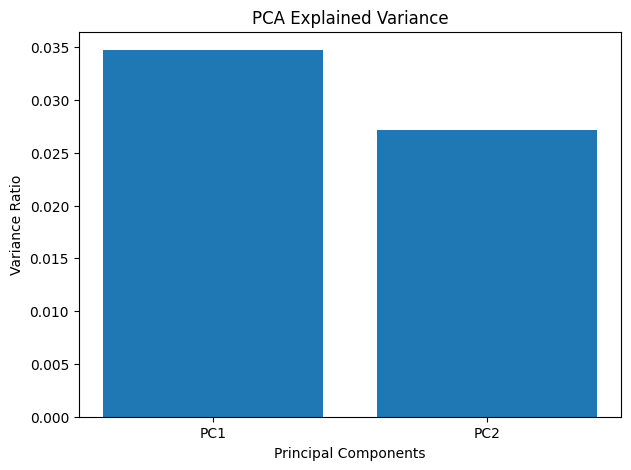

In [256]:
variance = pca.explained_variance_ratio_

plt.figure(figsize=(7,5))

plt.bar(['PC1', 'PC2'], variance)

plt.title('PCA Explained Variance')
plt.xlabel('Principal Components')
plt.ylabel('Variance Ratio')

plt.show()

In [257]:
pc1 = pca.explained_variance_ratio_[0] * 100

pc2 = pca.explained_variance_ratio_[1] * 100

total = pc1 + pc2

print("PC1:", round(pc1, 2), "%")

print("PC2:", round(pc2, 2), "%")

print("Total Variance:", round(total, 2), "%")

PC1: 3.47 %
PC2: 2.71 %
Total Variance: 6.19 %


1. How much variance is captured by the first two components?

Total variance: 6.19%
The first two principal components together explain only 6.19% of the total variance in the dataset. This means most of the information is spread across the remaining components.

2. Are clusters clearly separable in PCA space?

No. The clusters are not clearly separated in the PCA scatter plot. There is considerable overlap between clusters, making it difficult to identify distinct groups using only the first two principal components.

3. Do both clustering methods show similaR separation patterns?

Yes, both K-Means and Agglomerative Clustering show broadly similar patterns, with overlapping clusters and no clear boundaries in the PCA plots. However, the exact cluster assignments may differ because the two algorithms use different clustering approaches.
The first two PCA components capture only 6.19% of the total variance. Therefore, the 2D PCA visualization does not represent the complete structure of the dataset. Both clustering methods identify groups, but those groups are not clearly separable in the two-dimensional PCA space.












This might also interest you.